In [ ]:
from rich.console import Console
from dotenv import load_dotenv
import re, time, os

from typing_extensions import Literal
from IPython.display import Image, display

from utils import format_messages, format_message
from rich.markdown import Markdown

In [2]:
load_dotenv()
console = Console()

In [3]:
from langchain_core.tools.retriever import create_retriever_tool
from langchain_core.vectorstores import InMemoryVectorStore
from langchain_core.embeddings import Embeddings
from langchain_core.messages import SystemMessage, ToolMessage, HumanMessage

from langchain_community.document_loaders import WebBaseLoader
from langchain.embeddings import init_embeddings
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_google_genai._common import GoogleGenerativeAIError
from langchain.chat_models import init_chat_model

from langgraph.graph import END, START, MessagesState, StateGraph

C:\Users\Parth\AppData\Local\Temp\ipykernel_11756\1197549621.py:6: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import WebBaseLoader
USER_AGENT environment variable not set, consider setting it to identify your requests.


In [4]:
DATA_SOURCE_URLs = [
    "https://lilianweng.github.io/posts/2025-05-01-thinking/",
    "https://lilianweng.github.io/posts/2024-11-28-reward-hacking/",
    "https://lilianweng.github.io/posts/2024-07-07-hallucination/",
    "https://lilianweng.github.io/posts/2024-04-12-diffusion-video/",
]

## Load docs
docs = [WebBaseLoader(url).load() for url in DATA_SOURCE_URLs]
doc_list = [item for sublist in docs for item in sublist]

console.print("\n[bold green]▣ Document loaded into RAM.[/bold green]")

## Split documents into manageable chunks
text_splitter = RecursiveCharacterTextSplitter.from_tiktoken_encoder(
    chunk_size    = 2000,
    chunk_overlap = 50 
)

splitted_docs = text_splitter.split_documents(doc_list)
console.print("\n[bold green]▣ Document splitted into chunks.[/bold green]")

▣ Document loaded into RAM.

▣ Document splitted into chunks.

- **Below class `RateLimitedEmbeddings` is just designed to use free tier `gemini embedding` models safely. no rocket science applied..😊**

In [5]:
class RateLimitedEmbeddings(Embeddings):
    """Gemini free tier: 30k embed tokens/minute. Batch and wait on 429."""

    TPM_LIMIT = 25_000  # headroom under the 30k free-tier cap
    WINDOW_S  = 60.0

    def __init__(self, inner: Embeddings):
        self.inner = inner
        self._used = 0
        self._window_start = time.monotonic()

    @staticmethod
    def _estimate_tokens(texts: list[str]) -> int:
        return sum(max(1, len(text) // 4) for text in texts)

    def _await_quota(self, needed: int) -> None:
        elapsed = time.monotonic() - self._window_start
        if elapsed >= self.WINDOW_S:
            self._used = 0
            self._window_start = time.monotonic()
            elapsed = 0.0
        if self._used + needed <= self.TPM_LIMIT:
            return
        wait = self.WINDOW_S - elapsed + 1.0
        console.print(f"[yellow]□ Embed quota: waiting {wait:.0f}s...[/yellow]")
        time.sleep(wait)
        self._used = 0
        self._window_start = time.monotonic()

    def _embed_batch(self, texts: list[str]) -> list[list[float]]:
        for attempt in range(6):
            try:
                vectors = self.inner.embed_documents(texts, batch_size=len(texts))
                self._used += self._estimate_tokens(texts)
                return vectors
            except GoogleGenerativeAIError as exc:
                err = str(exc)
                if "RESOURCE_EXHAUSTED" not in err and "429" not in err:
                    raise
                match = re.search(r"retry in ([0-9.]+)s", err, re.I)
                wait = float(match.group(1)) + 1.0 if match else 30.0 * (attempt + 1)
                console.print(f"[yellow]□ 429 quota hit; retrying in {wait:.0f}s (attempt {attempt + 1})[/yellow]")
                time.sleep(wait)
                self._used = 0
                self._window_start = time.monotonic()
        raise RuntimeError("Embedding failed after retries (quota).")

    def embed_documents(self, texts: list[str]) -> list[list[float]]:
        embeddings: list[list[float]] = []
        i = 0
        n = len(texts)
        while i < n:
            batch: list[str] = []
            batch_tokens = 0
            while i < n:
                chunk_tokens = self._estimate_tokens([texts[i]])
                if batch and batch_tokens + chunk_tokens > self.TPM_LIMIT:
                    break
                batch.append(texts[i])
                batch_tokens += chunk_tokens
                i += 1
            self._await_quota(batch_tokens)
            console.print(f"[cyan]□ Embedding chunks {i - len(batch) + 1}–{i} / {n}[/cyan]")
            embeddings.extend(self._embed_batch(batch))
        return embeddings

    def embed_query(self, text: str) -> list[float]:
        self._await_quota(self._estimate_tokens([text]))
        vector = self.inner.embed_query(text)
        self._used += self._estimate_tokens([text])
        return vector

In [6]:
## Embeddings and vector store
embeddings = RateLimitedEmbeddings(
    init_embeddings("google_genai:gemini-embedding-001")
)

vectorstore = InMemoryVectorStore.from_documents(
    documents = splitted_docs,
    embedding = embeddings,
)

## Retriever
retriever = vectorstore.as_retriever()
console.print("\n[bold green]▣ Vector store ready.[/bold green]")

□ Embedding chunks 1–14 / 28

□ Embed quota: waiting 54s...

□ Embedding chunks 15–28 / 28

▣ Vector store ready.

In [7]:
## Retriever tool 
retriever_tool = create_retriever_tool(
    retriever   = retriever,
    name        = "retriever_blog_post",
    description = "Search and return information about Lilian Weng blog posts." 
)

## Testing retriever
test_result = retriever_tool.invoke({'query' : 'Types of reward hacking.'})

In [8]:
print(test_result)

Experiments in two RL environments, CoinRun and Maze, demonstrated the importance of randomization during training. If during training, the coin or the cheese is placed at a fixed position (i.e. right end of the level or upper right corner of the maze) but testing in the env where the coin or cheese is placed at random, the agent would just run to the fixed position without obtaining the coin or cheese at test time. A conflict arises when a visual feature (e.g., cheese or coin) and a positional feature (e.g., upper-right or right end) are inconsistent during test time, leading the trained model to prefer the positional feature. I would like to point out that, in these two examples, the reward-result gaps are clear but such type of biases are unlikely to be so obvious in most real-world cases.


The impact of randomizing the position of the coin during training. When the coin is placed at random for {0, 2, 3, 6, 11}% of the time during training (x-axis), the frequency of the agent navig

In [9]:
def _set_env(var : str) -> None:
    """
    Set environment variable if not alread set.
    """
    if not os.environ.get(var):
        raise EnvironmentError(f"{var} not found.!!")


_set_env("GOOGLE_API_KEY")

llm = init_chat_model(
    "gemini-3.5-flash",
    model_provider = "google_genai",
    timeout        = 60,
    max_retries    = 5,
    temperature    = 0,
)

In [10]:
## Setup tools and bind them with LLM
tools = [retriever_tool]
tools_by_name = {tool.name : tool for tool in tools}

## Bind tools to LLM for agent functionality
llm_with_tools = llm.bind_tools(tools)

In [11]:
class State(MessagesState):
    """Extended state that includes a summary field for context compression."""
    summary  : str

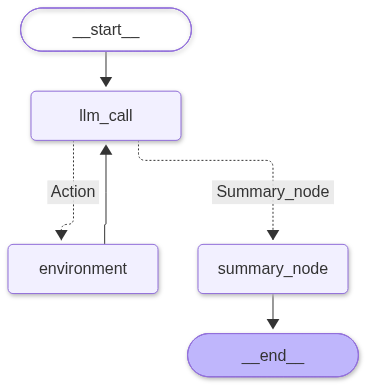

In [12]:
RAG_PROMPT = """
You are a helpful assistant tasked with retrieving information from a series of technical blog posts by Lilian Weng. 
Clarify the scope of research with the user before using your retrieval tool to gather context. Reflect on any context you fetch, and
proceed until you have sufficient context to answer the user's research request.
"""

SUMMARIZATION_PROMPT = """
Summarize the full chat history and all tool feedback to 
give an overview of what the user asked about and what the agent did.
"""

def llm_call(state : MessagesState) -> dict:
    """
    Execute LLM call with system prompt and message history.
    
    Args:
        state: Current conversation state
        
    Returns:
        Dictionary with new messages
    """
    messages = [SystemMessage(content = RAG_PROMPT)] + state['messages']
    response = llm_with_tools.invoke(messages)
    return {'messages' : [response]}


def tool_node(state : MessagesState) -> dict:
    """
    Execute tool calls and return results.
    
    Args:
        state: Current conversation state with tool calls
        
    Returns:
        Dictionary with tool results
    """
    result = []
    for tool_call in state['messages'][-1].tool_calls:
        tool = tools_by_name[tool_call['name']]
        observation = tool.invoke(tool_call['args'])
        result.append(ToolMessage(content = observation, tool_call_id = tool_call['id']))
    return {'messages' : result}

def summary_node(state : MessagesState) -> dict:
    """
    Generate a summary of the conversation and tool interactions.
    
    Args:
        state: Current conversation state
        
    Returns:
        Dictionary with conversation summary
    """
    messages = (
        [SystemMessage(content = SUMMARIZATION_PROMPT)] 
        + state['messages']
        + [HumanMessage(content="SUmmarize the above conversation and all tool execution result.")]
    )
    result = llm.invoke(messages)
    return {'summary' : result.content}

def should_continue(state : MessagesState) -> Literal["Action", "Summary_node"]:
    """
    Determine next step based on whether LLM made tool calls.
    
    Args:
        state: Current conversation state
        
    Returns:
        Next node to execute
    """
    messages = state['messages']
    last_message = messages[-1]

    if last_message.tool_calls:
        return "Action"
    return "Summary_node"



## RAG Flow
agent_builder = StateGraph(State)

agent_builder.add_node("llm_call", llm_call)
agent_builder.add_node("environment", tool_node)
agent_builder.add_node("summary_node", summary_node)

agent_builder.add_edge(START, "llm_call")
agent_builder.add_conditional_edges(
    "llm_call",
    should_continue,
    {
        "Action"       : "environment",
        "Summary_node" : "summary_node" 
    }
)
agent_builder.add_edge("environment", "llm_call")
agent_builder.add_edge("summary_node", END)

Agent = agent_builder.compile()

display(Image(Agent.get_graph(xray = True).draw_mermaid_png()))

In [13]:
query = "Why does RL improve LLM reasoning according to the blogs ?"
result = Agent.invoke({"messages" : query})
format_message(result['messages'])

╭─────────────────────────────────────────────────── 🧑 Human ────────────────────────────────────────────────────╮
│ Why does RL improve LLM reasoning according to the blogs ?                                                      │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭───────────────────────────────────────────────────── 📝 AI ─────────────────────────────────────────────────────╮
│ To ensure I gather the most relevant information from Lilian Weng's blog posts, could you clarify the scope of  │
│ your request?                                                                                                   │
│                                                                                                                 │
│ For instance, would you like me to focus on:                                                                    │
│ 1. **Specific mechanisms & paradigms:** e.g., RLHF / RLAIF, process vs. outcome supervision, reward model       │
│ design, or Search/Monte Carlo Tree Search (MCTS) combined with RL?                                              │
│ 2. **Key blog posts/topics:** e.g., posts specifically focusing on reasoning in LLMs, agent                     │
│ reflection/self-critique, or RLHF in general?                                                                   │
│ 3. **A broad comprehensive overview:** Covering all mentioned ways RL contributes to reasoning capabilities     │
│ across all relevant posts?                                                                                      │
│                                                                                                                 │
│ Let me know your preference, or if there is any particular aspect you'd like me to emphasize!                   │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

In [14]:
Markdown(result['summary'][0]['text'])

Overview of Chat History and Tool Execution                                                                        

 • User's Request: The user asked why Reinforcement Learning (RL) improves Large Language Model (LLM) reasoning    
   according to the blogs (Lilian Weng's posts).                                                                   
 • Agent Action: In accordance with the instruction to clarify the research scope before invoking retrieval tools, 
   the agent responded by asking the user to specify their desired scope (e.g., specific mechanisms like           
   RLHF/process supervision/MCTS, specific topics, or a broad overview across all relevant posts).                 
 • Tool Execution Status: No retrieval or search tools have been executed yet, as the agent is awaiting scope      
   clarification from the user.

> **Summarization Tool.**

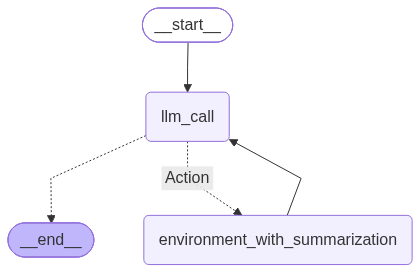

In [16]:
TOOL_SUMMARIZATION_PROMPT = """
    You will be provided a doc from a RAG system.
    Summarize the docs, ensuring to retain all relevant / essential information.
    Your goal is simply to reduce the size of the doc (tokens) to a more manageable size.
"""

def should_continue(state : MessagesState) -> Literal["environment", END]:
    """Decide if we should continue the loop or stop based upon whether the LLM made a tool call"""

    messages = state["messages"]
    last_message = messages[-1]

    if last_message.tool_calls:
        return "Action"

    return END

def tool_node_with_summarization(state : dict):
    """Performs the tool call"""

    result = []
    for tool_call in state["messages"][-1].tool_calls:
        tool = tools_by_name[tool_call["name"]]
        observation = tool.invoke(tool_call["args"])
        # Summarize the doc
        summary = llm.invoke([{"role":"system",
                              "content": TOOL_SUMMARIZATION_PROMPT},
                              {"role":"user",
                               "content":observation}])
        result.append(ToolMessage(content=summary.content, tool_call_id=tool_call["id"]))
    return {"messages": result}


agent_builder = StateGraph(State)

agent_builder.add_node("llm_call", llm_call)
agent_builder.add_node("environment_with_summarization", tool_node_with_summarization)


agent_builder.add_edge(START, "llm_call")
agent_builder.add_conditional_edges(
    "llm_call",
    should_continue,
    {
        "Action": "environment_with_summarization",
        END: END,
    },
)
agent_builder.add_edge("environment_with_summarization", "llm_call")


agent = agent_builder.compile()

display(Image(agent.get_graph(xray=True).draw_mermaid_png()))


In [17]:
query = "Why does RL improve LLM reasoning according to the blogs?"
result = agent.invoke({"messages": query})
format_messages(result['messages'])

╭─────────────────────────────────────────────────── 🧑 Human ────────────────────────────────────────────────────╮
│ Why does RL improve LLM reasoning according to the blogs?                                                       │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭───────────────────────────────────────────────────── 📝 AI ─────────────────────────────────────────────────────╮
│ To ensure I gather the most relevant information from Lilian Weng's blog posts, could you please clarify the    │
│ scope of your request?                                                                                          │
│                                                                                                                 │
│ Specifically:                                                                                                   │
│ 1. **Focus Areas:** Are you interested in general Reinforcement Learning (RL) concepts, Reinforcement Learning  │
│ from Human/AI Feedback (RLHF / RLAIF), or specific applications like process reward models, Chain-of-Thought    │
│ (CoT) reasoning, and search/tree-based methods (e.g., MCTS)?                                                    │
│ 2. **Depth & Topics:** Should I focus broadly across all her posts related to LLMs and RL, or focus             │
│ specifically on posts dealing with reasoning, math/code problem solving, and alignment?                         │
│                                                                                                                 │
│ Once you confirm your preferred scope, I'll proceed to retrieve and summarize the key insights!                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

In [24]:
Markdown(result['messages'][1].content[0]['text'])

To ensure I gather the most relevant information from Lilian Weng's blog posts, could you please clarify the scope 
of your request?                                                                                                   

Specifically:                                                                                                      

 1 Focus Areas: Are you interested in general Reinforcement Learning (RL) concepts, Reinforcement Learning from    
   Human/AI Feedback (RLHF / RLAIF), or specific applications like process reward models, Chain-of-Thought (CoT)   
   reasoning, and search/tree-based methods (e.g., MCTS)?                                                          
 2 Depth & Topics: Should I focus broadly across all her posts related to LLMs and RL, or focus specifically on    
   posts dealing with reasoning, math/code problem solving, and alignment?                                         

Once you confirm your preferred scope, I'll proceed to retrieve and summarize the key insights!